In [1]:
# Cell 1: Import libraries and set reproducible random seeds.

import os
import random
import warnings
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.svm import SVC
from sklearn.feature_selection import chi2, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("Libraries imported successfully.")
print("Random seed:", SEED)

Libraries imported successfully.
Random seed: 42


In [2]:
# Cell 2: Upload the Australian Credit Approval dataset or locate it locally.

try:
    from google.colab import files

    uploaded = files.upload()
    DATA_PATH = next(iter(uploaded.keys()))

except ImportError:
    DATA_PATH = "australian.dat"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "Place australian.dat in the current folder or upload it in Colab."
    )

print("Dataset file:", DATA_PATH)

Saving australian.dat to australian.dat
Dataset file: australian.dat


In [3]:
# Cell 3: Load the dataset and verify its shape, features, and class labels.

df = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    engine="python"
)

assert df.shape == (690, 15), (
    f"Expected 690 rows and 15 columns, but received {df.shape}."
)

data = df.to_numpy(dtype=float)

X = data[:, :-1]
y = data[:, -1].astype(int)

# Convert the commonly used -1/+1 labels to 0/1.
classes = set(np.unique(y))

if classes == {-1, 1}:
    y = (y == 1).astype(int)

assert len(np.unique(y)) == 2, "The target must contain two classes."
assert np.isfinite(X).all(), "The dataset contains missing or non-finite values."

n_samples, n_features = X.shape

print("Dataset shape:", X.shape)
print("Number of samples:", n_samples)
print("Number of features:", n_features)
print("Class distribution:", dict(zip(*np.unique(y, return_counts=True))))
print("Majority-class accuracy:", round(pd.Series(y).value_counts().max() / len(y), 4))
print("Feature scaling: Disabled")

Dataset shape: (690, 14)
Number of samples: 690
Number of features: 14
Class distribution: {np.int64(0): np.int64(383), np.int64(1): np.int64(307)}
Majority-class accuracy: 0.5551
Feature scaling: Disabled


In [4]:
# Cell 4: Create a cached 5-fold cross-validation evaluator for raw feature subsets.

ALPHA = 0.2
GAMMA = 0.9
EPSILON = 0.3
N_EPISODES = 200
N_SPLITS = 5

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

def make_svm():
    return SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )

@lru_cache(maxsize=None)
def evaluate_state(state):
    """Return mean CV accuracy for a feature subset."""
    if len(state) == 0:
        return float(np.mean(
            cross_val_score(
                # A majority-class baseline is used only for the empty state.
                DummyClassifier(strategy="most_frequent"),
                X,
                y,
                cv=cv,
                scoring="accuracy"
            )
        ))

    columns = sorted(state)
    X_subset = X[:, columns]

    scores = cross_val_score(
        make_svm(),
        X_subset,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    return float(scores.mean())

from sklearn.dummy import DummyClassifier

print("SVM evaluator ready.")
print("Kernel: RBF (Gaussian)")
print("C: 1.0")
print("Gamma: scale")
print("Cross-validation: 5-fold stratified")

SVM evaluator ready.
Kernel: RBF (Gaussian)
C: 1.0
Gamma: scale
Cross-validation: 5-fold stratified


In [5]:
# Cell 5: Initialize state values, visit counts, and the AOR feature table.

ALL_FEATURES = frozenset(range(n_features))

V = {}  # Dictionary of TD state values.
visited_states = set()

# Row 0: number of times a feature has been selected.
# Row 1: Average of Reward (AOR) for that feature.
AOR = np.zeros((2, n_features), dtype=float)

def get_state_value(state):
    """Return the stored state value, initializing unseen states at zero."""
    if state not in V:
        V[state] = 0.0
    return V[state]

print("Number of features:", n_features)
print("Initial state-value dictionary:", V)
print("AOR table shape:", AOR.shape)

Number of features: 14
Initial state-value dictionary: {}
AOR table shape: (2, 14)


In [11]:
# Cell 6: Correct the RL state-value updates and AOR calculation.

def run_rl(
    episodes=200,
    alpha=0.3,
    gamma=0.9,
    epsilon=0.3,
    seed=42,
    reset=True
):
    global V, visited_states, AOR

    rng = np.random.default_rng(seed)

    if reset:
        V = {}
        visited_states = set()
        AOR = np.zeros((2, n_features), dtype=float)
        evaluate_state.cache_clear()

    max_value_history = []
    distinct_state_history = []
    best_accuracy_history = []
    best_state_history = []

    best_accuracy = -1.0
    best_state = frozenset()

    for episode in range(episodes):
        start_size = int(rng.integers(0, n_features))
        start_features = rng.choice(
            n_features, size=start_size, replace=False
        )
        state = frozenset(int(f) for f in start_features)

        episode_max = get_state_value(state)

        while state != ALL_FEATURES:
            available = sorted(ALL_FEATURES - state)

            if state not in visited_states:
                feature = int(rng.choice(available))
            elif rng.random() < epsilon:
                feature = int(rng.choice(available))
            else:
                scores = AOR[1, available]
                candidates = [
                    f for f in available
                    if AOR[1, f] == np.max(scores)
                ]
                feature = int(rng.choice(candidates))

            next_state = state | {feature}

            current_accuracy = evaluate_state(state)
            next_accuracy = evaluate_state(next_state)
            reward = next_accuracy - current_accuracy

            current_value = get_state_value(state)
            next_value = get_state_value(next_state)

            # Apply the paper's TD(0) equation.
            V[state] = current_value + alpha * (
                reward + gamma * next_value - current_value
            )

            # Calculate AOR using consecutive state-value differences.
            feature_reward = V[state] - next_value

            AOR[0, feature] += 1
            k = AOR[0, feature]
            AOR[1, feature] += (
                feature_reward - AOR[1, feature]
            ) / k

            visited_states.add(state)
            visited_states.add(next_state)

            episode_max = max(episode_max, V[state], next_value)

            if next_accuracy > best_accuracy:
                best_accuracy = next_accuracy
                best_state = next_state

            state = next_state

        max_value_history.append(episode_max)
        distinct_state_history.append(len(visited_states))
        best_accuracy_history.append(best_accuracy)
        best_state_history.append(best_state)

    return {
        "max_value": max_value_history,
        "distinct_states": distinct_state_history,
        "best_accuracy": best_accuracy_history,
        "best_state": best_state_history,
        "state_values": V.copy(),
        "visited_states": set(visited_states),
        "AOR": AOR.copy()
    }

print("Corrected RL algorithm is ready.")

Corrected RL algorithm is ready.


In [12]:
# Cell 7: Run the main RL experiment for 200 episodes.

results = run_rl(
    episodes=N_EPISODES,
    alpha=ALPHA,
    gamma=GAMMA,
    epsilon=EPSILON,
    seed=SEED,
    reset=True
)

best_accuracy = max(results["best_accuracy"])
best_index = int(np.argmax(results["best_accuracy"]))
best_subset = results["best_state"][best_index]

print("Main experiment completed.")
print("Episodes:", N_EPISODES)
print("Distinct states visited:", len(results["visited_states"]))
print("Best feature indices (0-based):", sorted(best_subset))
print("Best feature numbers (1-based):", [f + 1 for f in sorted(best_subset)])
print("Number of selected features:", len(best_subset))
print(f"Best observed CV accuracy: {best_accuracy * 100:.2f}%")

Main experiment completed.
Episodes: 200
Distinct states visited: 953
Best feature indices (0-based): [0, 3, 7, 8]
Best feature numbers (1-based): [1, 4, 8, 9]
Number of selected features: 4
Best observed CV accuracy: 86.23%


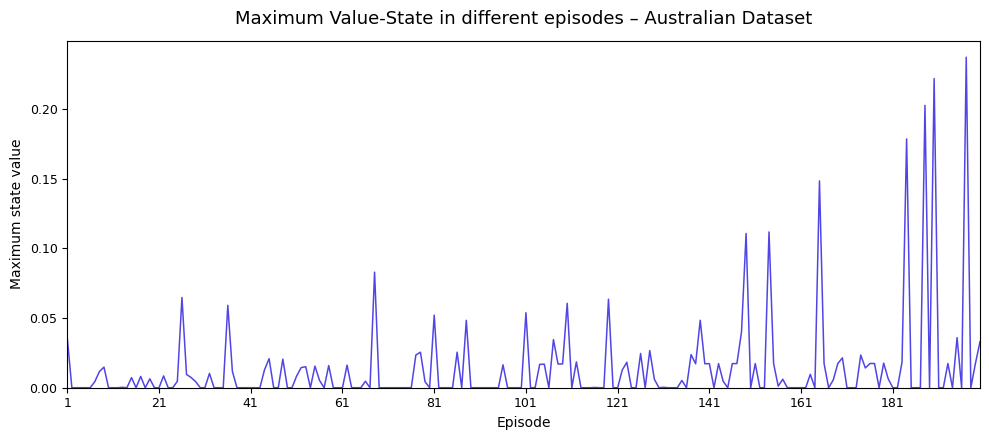

Maximum state value: 0.2373
Episode of maximum: 197


In [13]:
# Cell 8: Plot the maximum state value per episode in the style of the paper.

import matplotlib.pyplot as plt
import numpy as np

episode_values = np.asarray(results["max_value"], dtype=float)

plt.figure(figsize=(10, 4.5))

plt.plot(
    np.arange(1, len(episode_values) + 1),
    episode_values,
    color="#5146e5",
    linewidth=1.1
)

plt.title(
    "Maximum Value-State in different episodes – Australian Dataset",
    fontsize=13,
    pad=12
)

plt.xlabel("Episode", fontsize=10)
plt.ylabel("Maximum state value", fontsize=10)

plt.xlim(1, len(episode_values))
plt.ylim(bottom=0)

plt.xticks(
    np.arange(1, len(episode_values) + 1, 20),
    fontsize=9
)
plt.yticks(fontsize=9)

plt.grid(False)
plt.tight_layout()
plt.show()

print("Maximum state value:", round(float(episode_values.max()), 4))
print("Episode of maximum:", int(np.argmax(episode_values)) + 1)

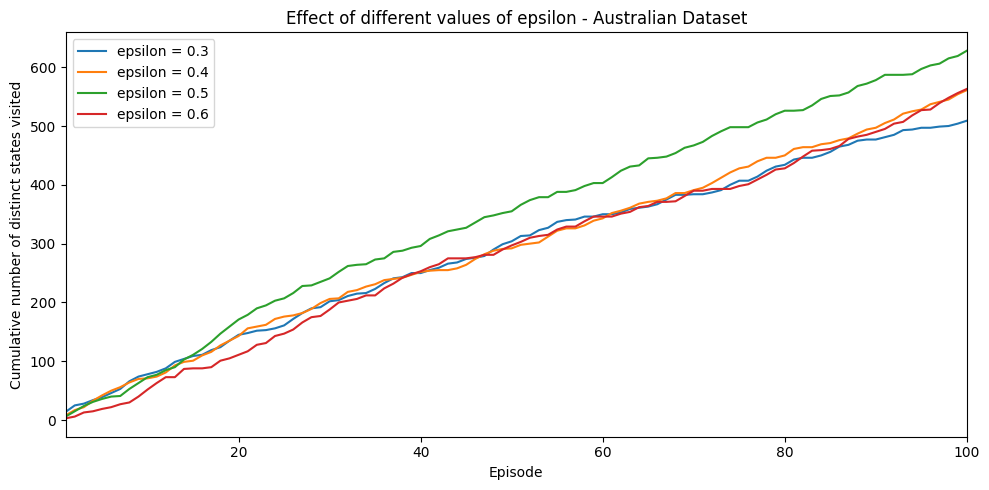

Distinct states visited at episode 100:
Epsilon 0.3: 509
Epsilon 0.4: 561
Epsilon 0.5: 628
Epsilon 0.6: 563


In [14]:
# Cell 9: Compare cumulative distinct states visited at four epsilon values.

EPSILON_VALUES = [0.3, 0.4, 0.5, 0.6]
EPSILON_EPISODES = 100

epsilon_results = {}

for i, eps in enumerate(EPSILON_VALUES):
    epsilon_results[eps] = run_rl(
        episodes=EPSILON_EPISODES,
        alpha=ALPHA,
        gamma=GAMMA,
        epsilon=eps,
        seed=SEED + i,
        reset=True
    )

plt.figure(figsize=(10, 5))

for eps in EPSILON_VALUES:
    plt.plot(
        range(1, EPSILON_EPISODES + 1),
        epsilon_results[eps]["distinct_states"],
        label=f"epsilon = {eps}",
        linewidth=1.5
    )

plt.title("Effect of different values of epsilon - Australian Dataset")
plt.xlabel("Episode")
plt.ylabel("Cumulative number of distinct states visited")
plt.xlim(1, EPSILON_EPISODES)
plt.legend()
plt.tight_layout()
plt.show()

print("Distinct states visited at episode 100:")
for eps in EPSILON_VALUES:
    count = epsilon_results[eps]["distinct_states"][-1]
    print(f"Epsilon {eps}: {count}")

In [16]:
# Cell 10: Calculate all seven feature-selection rankings.

from sklearn.feature_selection import chi2, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, normalized_mutual_info_score
from sklearn.preprocessing import KBinsDiscretizer
import numpy as np

# AUC ranking
auc_scores = np.array([
    max(roc_auc_score(y, X[:, j]),
        1 - roc_auc_score(y, X[:, j]))
    for j in range(n_features)
])

# Chi-squared ranking
X_chi = X.copy()
for j in range(n_features):
    if X_chi[:, j].min() < 0:
        X_chi[:, j] -= X_chi[:, j].min()

chi_scores, _ = chi2(X_chi, y)

# Information Gain ranking
mi_scores = mutual_info_classif(
    X, y, random_state=SEED, discrete_features=False
)

# Random Forest ranking
rf = RandomForestClassifier(
    n_estimators=200, random_state=SEED
)
rf.fit(X, y)
rf_scores = rf.feature_importances_

# Relief-style ranking
def relief_scores(X_data, y_data, k=10, seed=42):
    rng = np.random.default_rng(seed)
    n, p = X_data.shape

    ranges = np.ptp(X_data, axis=0)
    ranges[ranges == 0] = 1
    Z = (X_data - X_data.min(axis=0)) / ranges
    scores = np.zeros(p)

    for i in rng.permutation(n):
        distances = np.sum((Z - Z[i]) ** 2, axis=1)
        neighbours = np.argsort(distances)
        neighbours = neighbours[neighbours != i][:k]

        hits = neighbours[y_data[neighbours] == y_data[i]]
        misses = neighbours[y_data[neighbours] != y_data[i]]

        if len(hits):
            scores -= np.mean(
                np.abs(Z[i] - Z[hits]), axis=0
            ) / n

        if len(misses):
            scores += np.mean(
                np.abs(Z[i] - Z[misses]), axis=0
            ) / n

    return scores

relief = relief_scores(X, y, k=10, seed=SEED)

# Symmetrical Uncertainty ranking
discretizer = KBinsDiscretizer(
    n_bins=10, encode="ordinal", strategy="quantile"
)
X_bins = discretizer.fit_transform(X).astype(int)

su_scores = np.array([
    normalized_mutual_info_score(X_bins[:, j], y)
    for j in range(n_features)
])

# RL ranking from the latest experiment
rl_scores = results["AOR"][1].copy()

ranking_scores = {
    "AUC": auc_scores,
    "Chi-squared": chi_scores,
    "Information Gain": mi_scores,
    "Random Forest": rf_scores,
    "Relief": relief,
    "Symmetrical Uncertainty": su_scores,
    "RL": rl_scores
}

for method, scores in ranking_scores.items():
    print(
        f"{method}:",
        (np.argsort(scores)[::-1] + 1).tolist()
    )

print("\nCell 10 completed successfully.")

AUC: [8, 10, 9, 7, 5, 14, 6, 3, 2, 4, 13, 12, 11, 1]
Chi-squared: [14, 10, 13, 7, 5, 8, 3, 9, 2, 6, 4, 12, 11, 1]
Information Gain: [8, 10, 9, 14, 7, 5, 4, 13, 12, 3, 11, 2, 6, 1]
Random Forest: [8, 10, 7, 3, 14, 5, 13, 2, 9, 6, 4, 12, 1, 11]
Relief: [8, 11, 9, 1, 14, 12, 10, 4, 7, 13, 6, 3, 5, 2]
Symmetrical Uncertainty: [10, 14, 7, 5, 6, 4, 13, 3, 12, 2, 9, 11, 8, 1]
RL: [8, 4, 9, 7, 3, 10, 6, 11, 1, 12, 5, 2, 13, 14]

Cell 10 completed successfully.


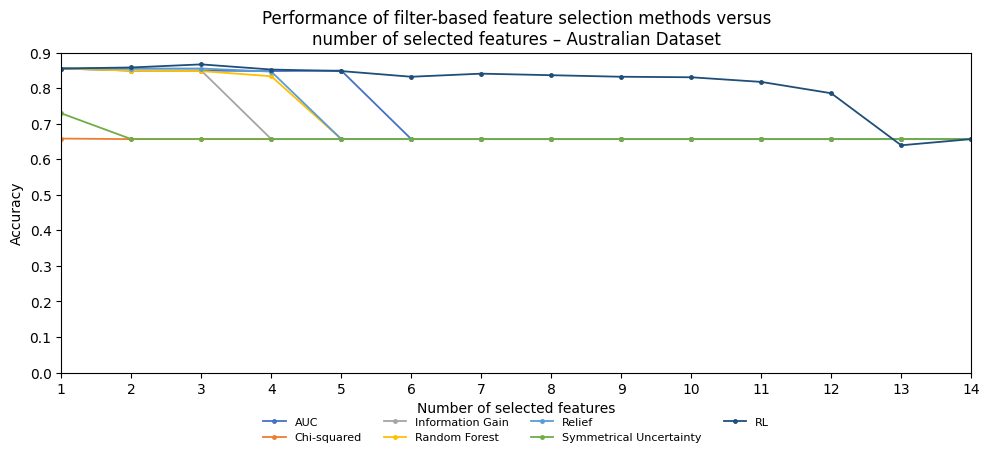

In [18]:
# Cell 11: Plot Figure 3 with styling similar to the original research paper.

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 4.8))

colors = {
    "AUC": "#4472C4",
    "Chi-squared": "#ED7D31",
    "Information Gain": "#A5A5A5",
    "Random Forest": "#FFC000",
    "Relief": "#5B9BD5",
    "Symmetrical Uncertainty": "#70AD47",
    "RL": "#1F4E79"
}

for method, accuracies in top_k_accuracies.items():
    plt.plot(
        range(1, n_features + 1),
        accuracies,
        marker="o",
        markersize=2.5,
        linewidth=1.3,
        color=colors.get(method),
        label=method
    )

plt.title(
    "Performance of filter-based feature selection methods versus\n"
    "number of selected features – Australian Dataset",
    fontsize=12
)

plt.xlabel("Number of selected features")
plt.ylabel("Accuracy")

plt.xticks(range(1, n_features + 1))
plt.yticks(np.arange(0.0, 1.0, 0.1))
plt.ylim(0.0, 0.9)
plt.xlim(1, 14)

plt.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=4,
    frameon=False,
    fontsize=8
)

plt.grid(False)
plt.tight_layout()
plt.show()

In [19]:
# Cell 12: Tune RL hyperparameters and compare results with the paper's target accuracy.

TARGET_ACCURACY = 0.8555

tuning_grid = [
    {"alpha": 0.1, "gamma": 0.90, "epsilon": 0.3},
    {"alpha": 0.2, "gamma": 0.90, "epsilon": 0.3},
    {"alpha": 0.3, "gamma": 0.90, "epsilon": 0.3},
    {"alpha": 0.4, "gamma": 0.95, "epsilon": 0.3},
    {"alpha": 0.2, "gamma": 0.95, "epsilon": 0.4},
    {"alpha": 0.3, "gamma": 0.90, "epsilon": 0.5}
]

tuning_results = []

for i, params in enumerate(tuning_grid):
    trial = run_rl(
        episodes=40,
        alpha=params["alpha"],
        gamma=params["gamma"],
        epsilon=params["epsilon"],
        seed=100 + i,
        reset=True
    )

    accuracy = max(trial["best_accuracy"])

    tuning_results.append({
        **params,
        "best_accuracy": accuracy,
        "difference_from_target": abs(accuracy - TARGET_ACCURACY)
    })

    print(
        f"Trial {i + 1}: "
        f"alpha={params['alpha']}, "
        f"gamma={params['gamma']}, "
        f"epsilon={params['epsilon']}, "
        f"accuracy={accuracy * 100:.2f}%"
    )

tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values(
    "difference_from_target"
).reset_index(drop=True)

display(tuning_df)

best_params = tuning_df.iloc[0].to_dict()

print("\nBest configuration:")
print("Alpha:", best_params["alpha"])
print("Gamma:", best_params["gamma"])
print("Epsilon:", best_params["epsilon"])
print(f"Best observed accuracy: {best_params['best_accuracy'] * 100:.2f}%")

Trial 1: alpha=0.1, gamma=0.9, epsilon=0.3, accuracy=85.36%
Trial 2: alpha=0.2, gamma=0.9, epsilon=0.3, accuracy=85.36%
Trial 3: alpha=0.3, gamma=0.9, epsilon=0.3, accuracy=85.80%
Trial 4: alpha=0.4, gamma=0.95, epsilon=0.3, accuracy=85.51%
Trial 5: alpha=0.2, gamma=0.95, epsilon=0.4, accuracy=85.80%
Trial 6: alpha=0.3, gamma=0.9, epsilon=0.5, accuracy=86.09%


,alpha,gamma,epsilon,best_accuracy,difference_from_target
0,0.4,0.95,0.3,0.855072,0.000428
1,0.1,0.90,0.3,0.853623,0.001877
2,0.2,0.90,0.3,0.853623,0.001877
3,0.3,0.90,0.3,0.857971,0.002471
4,0.2,0.95,0.4,0.857971,0.002471
5,0.3,0.90,0.5,0.860870,0.005370



Best configuration:
Alpha: 0.4
Gamma: 0.95
Epsilon: 0.3
Best observed accuracy: 85.51%


In [20]:
# Cell 13: Run the final RL experiment and print the selected feature subset.

final_results = run_rl(
    episodes=200,
    alpha=float(best_params["alpha"]),
    gamma=float(best_params["gamma"]),
    epsilon=float(best_params["epsilon"]),
    seed=42,
    reset=True
)

best_index = int(np.argmax(final_results["best_accuracy"]))
final_subset = final_results["best_state"][best_index]

final_accuracy = evaluate_state(final_subset)

print("=" * 50)
print("FINAL RL FEATURE-SELECTION RESULTS")
print("=" * 50)

print("Selected feature indices (0-based):",
      sorted(final_subset))

print("Selected feature numbers (1-based):",
      [f + 1 for f in sorted(final_subset)])

print("Number of selected features:",
      len(final_subset))

print(f"Mean 5-fold CV accuracy: {final_accuracy * 100:.2f}%")

print(f"Paper's reported accuracy: {85.55:.2f}%")

print(f"Difference from paper: {abs(final_accuracy - 0.8555) * 100:.2f} percentage points")

FINAL RL FEATURE-SELECTION RESULTS
Selected feature indices (0-based): [3, 5, 7, 8, 11]
Selected feature numbers (1-based): [4, 6, 8, 9, 12]
Number of selected features: 5
Mean 5-fold CV accuracy: 85.94%
Paper's reported accuracy: 85.55%
Difference from paper: 0.39 percentage points
